# Optimization 1 - The need for Calculus in ML

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configure Seaborn.
sns.set_style("whitegrid")
sns.set_palette("deep")

## 1 Optimization

### 1.1 Error vs Classifier

#### Best Separator

- A Classifier is a Decision Boundary that segregates data-points into two or more classes or groups.
- A Classifier is considered as "Best Separator" if distances of data-points from either side of the Decision Boundary is as large as possible.
- This maximum distance is calculated using Gain Function.

#### Gain Function

- Gain function helps us in deciding the best separator.
- Gain function calculates the distances of all data-points from either side of the Decision Boundary.
- The goal is to maximize this Gain function.

#### Error/Loss Function

- It is easy to minimize a function rather than trying to optimize it for maximum.
- When we try to minimize the value computed using a function, such function can be called as Error/Loss function.
- Gain function can be converted to Error function as: $\text{Error function} = -\text{Gain function}$.
- The goal is to minimize the loss or error value derived using Loss function.

Mathematical notation of a Error function:

$$
\large
\text{Error function}: f(x)
$$

#### Error

- Error value is computed using Error/Loss function.
- Error can be measured as percentage of misclassified observations.
- In ML context, Error is the **function of distance** of data-points $x$ from Decision Boundary calculated using its weight vector $w$.

In ML context Error function is a Multi-variate function:

$$
\large
\text{Error function}:\quad\,f(w, x, y) = -\sum_{i=1}^n \Biggl(\frac{w^T\,x_i\;+\;w_0}{\Vert{w}\Vert}\Biggr)\,\cdot\,y_i
$$

#### How to find minimum error?

1. Fit multiple classifiers on the data-points.
2. Choose the classifier with the lowest error.

#### Error function vs Classifier

![Error vs Classifier](images/error_vs_classifier.png)

1. Each classifier (line/Decision-Boundary) will have an error associated to it.
2. Error associated with the classifier tells us how bad the classifier is.
3. Error vs Classifier will be a **Multivariate function** $f(x)$ called as **Loss Function**.
4. The goal is to have **minimum error** i.e., identify classifier with lowest error.
5. In the above graph, Classifier #5 has the lowest error among all the $k$ number of classifiers.

#### Goal of Optimization

- A best classifier can be defined as a line with lowest error.
- A line in linear algebraic form is represented as: $w^T x\,+\,w_0 = 0$.
- In above equation Features $x$ are historical data and cannot be modified hence only weights $w$ and $w_0$ can be modified.
- Therefore goal of Optimization is to find optimal weights: $w$ vector and bias: $w_0$ so that the **error is minimum**.
- This Classifier that uses the optimal weights is considered as best classifier.

### 1.2 Linear Search Method

#### Problem Statement

Brute-force or linear search method of finding best weights between the range `[-10, +10]` with step size of `0.1`:

In [2]:
w_range = np.arange(-10, 10.1, 0.1)
len(w_range)

201

will have 201 unique values for each weight.

Suppose we need to find best weights for a line (2D Hyper-plane) which has three weight values: $w_1$, $w_2$ and $w_0$

In [3]:
wc = 3  # Number of weight parameters to train.
wr = 201  # Number of unique values.
ti_3 = 201**3  # Total number of iterations.

print("Weights count:", wc)
print("Total unique Values:", wr)
print(f"Iterations: {ti_3:,}")

Weights count: 3
Total unique Values: 201
Iterations: 8,120,601


In worst case scenario, finding best values for 3 weights from a set of 201 unique values takes: 8,120,601 iterations.

- Given $n$-dimensional data we will have to train $n + 1$ parameters.
- For example: In a three-dimensional space, we will have to train 4 parameters.
- 3D Hyperplane: $w_1 x_1\,+\,w_2 x_2\,+\,w_3 x_3\,+\,w_0 = 0$ requires training of: $\{w_1,\,w_2,\,w_3,\,w_0\}$  parameters.

In [4]:
t = 10**-6  # Time taken (in seconds) by a single CPU for one computation.
tr_3 = t * (201**3)  # Total compute time taken for training 3 parameters.
tr_4 = t * (201**4)  # Total compute time taken for training 4 parameters.
tr_5 = t * (201**5)  # Total compute time taken for training 5 parameters.
tr_6 = t * (201**6)  # Total compute time taken for training 6 parameters.

print("Training time for 3 parameters:", tr_3 // 1, "seconds")
print("Training time for 4 parameters:", tr_4 // 60, "minutes")
print("Training time for 5 parameters:", tr_5 // 60 // 60, "hours")
print("Training time for 6 parameters:", tr_6 // 60 // 60 // 24, "days")

Training time for 3 parameters: 8.0 seconds
Training time for 4 parameters: 27.0 minutes
Training time for 5 parameters: 91.0 hours
Training time for 6 parameters: 763.0 days


#### Need for Optimization

- So total time taken to train (identify best weights) a model with 5 parameters using Linear Search method roughly takes 91 hours.
- In real world scenario there will be thousands/millions/billions of parameters to train and Linear Search method cannot be scaled.
- Hence there is a need for some optimization technique to identify best weights.
- Optimization is achieved using **Gradient Descent** algorithm.
- Concepts from Calculus are used in Optimization techniques.

#### Why Optimization is focused only on weights?

Given the Mapping function for Binary Classification problem:

$$
\large
\begin{aligned}
\hat{y} = f(x) =&\; w_1 x_1 + w_2 x_2 + \ldots +  w_d x_d + w_0 \\[3pt]
                &\; \text{or}                                   \\[3pt]
               =&\; w^T x + w_0
\end{aligned}
$$

- The mapping function for a Binary Classifier has two vectors $\vec{w}$ and $\vec{x}$ in the dot product.
- The feature vector $\vec{x}$ is the **given dataset and cannot be modified**.
- Hence the only one remaining variable component in the dot product is weight vector $\vec{w}$.
- $w_0$ is also part of optimization.

### 1.3 Gradient Descent

Benefits of using Gradient Descent algorithm.

1. Finding **optimal values** for weight vector $\vec{w}$ and bias: $w_0$
2. Much **faster** than brute force (Linear Search method).
3. Gradient Descent uses **controlled searching**.
4. Gradient Descent achieves this using the concept of **Maxima** and **Minima**.

#### Maximization

- Process of finding maxima is called as **Maximization**.
- Process of finding the value of $x$, denoted as $x^*$, at which $f(x)$ takes **maximum possible value**.
- Here $x^*$ is called **maxima**.

$$
\large
\arg\max_{x^*} \; f(x)
$$

#### Minimization

- Process of finding minima is called as **Minimization**.
- Process of finding the value of $x$, denoted as $x^*$, at which $f(x)$ takes **minimum possible value**.
- Here $x^*$ is called **minima**.

$$
\large
\arg\min_{x^*} \; f(x)
$$

> **Note**:
>
> Calculus is used to find minima.

#### Minimization In ML Context

Minimization in ML context can be summarized as:

- If we consider the above Error/Loss function $l(D,\,\vec{w},\,w_0)$ as a function $f(x)$, we need to find the value of $x$ such that: $f(x)$ takes minimum possible value.
- For a given function $l(D,\,\vec{w},\,w_0)$ we need to find values of $\vec{w}$ and $w_0$ such that: $l(D,\,\vec{w},\,w_0)$ takes the minimum possible value:

Mathematical notation for minimization of Error function:

$$
\large
w^*, w_0^* = \arg\min_{w,\,w_0}\;l(D,\,\vec{w},\,w_0)
$$

### 1.4 Application of Mathematics

#### Topics

To reach the goal of finding minima we need to understand below chain of concepts that are applied on functions:

1. **Maxima/Minima**: Maxima/Minima is found using Partial Differentiation concept from Differential Calculus.
2. **Partial Differentiation**: Branch of Differential Calculus that studies derivatives of functions of multiple variables.
3. **Differentiation**:
   - Differentiation is the process of computing Derivatives of functions.
   - Partial Differentiation is a specialization of Differentiation of functions of multiple variables.
4. **Derivatives**: Applying Differentiation on a function, using **Limits**, produces its Derivative(s).
5. Derivatives helps us calculate **Slope of a Tangent**.
6. Horizontal slope of the Tangents (zero derivatives) are the indicators of critical-points.
7. Critical-points are good candidates for **Optima** (Maxima/Minima/Saddle point).

#### Questions

Questions that helps us understand the importance of above listed topics to reach the end goal of finding minima:

1. What are Functions? and types of Functions.
2. Understand Continuous and Discontinuous functions.
3. How to find derivative of a Continuous function?
4. After obtaining derivative, relationship between derivatives, slope and tangent.
5. How slope helps in Calculus?
6. How slope helps in Minimization?

## 2 Mathematical Notations

Updating the Mathematical notations in previous notes with new mathematical notations for Optimization.

### 2.1 Dataset

#### Mathematical Notation

A labeled dataset $D$ is represented as:

$$
\large
D\,:=\,\biggl\{\bigl(x_i,\,y_i \bigr)\;;\;x_i\in\mathbb{R}^d\;;\;y_i\in\bigl\{-1,\,+1\bigr\}\biggr\}_{i=1}^n
$$

Where,

- $D$ is the Dataset containing $x$ and $y$
- $x$ are feature vectors of datatype Real numbers $\mathbb{R}$
- $y$ are labels having either $-1$ or $+1$ as its value
- $n$ is the total number of rows in the dataset
- $d$ is the dimension/size i.e., total number of elements in the feature vector $x$

### 2.2 Mapping Function

#### Mathematical Notation

Mapping function for Binary Classification: nD Hyperplane

$$
\large
\begin{aligned}
\hat{y} = f(x) =&\; w_1 x_1 + w_2 x_2 + \ldots +  w_d x_d + w_0 \\[3pt]
                &\; \text{or}                                   \\[3pt]
               =&\; w^T x + w_0
\end{aligned}
$$

Where,

- $\hat{y}$ is the predicted value
- $w$ is the weight vector
- $x$ are feature vectors

### 2.3 Gain Function

#### Mathematical Notation

Equation of Gain Function for Binary Classification:

$$
\large
g(x,\,y,\,\vec{w},\,w_0) = \frac{1}{n}\,\sum_{i=1}^n\,\Biggl(\frac{w^T\,x^{(i)}\;+\;w_0}{\Vert{w}\Vert}\Biggr)\,\cdot\,y^{(i)}
$$

Gain function is:

- For all the given data-points, product between its distance and its class label is summed up to obtain a single scalar value.
- Here distance is the distance of a data-point from the Decision boundary.

#### Optimization of Gain Function

Equation for Optimization of Gain Function for Binary Classification:

$$
\large
\begin{aligned}
w^*,\,w_0^* &\;=\;\arg\max_{w,\,w_0}\;\;g(x,\,y,\,\vec{w},\,w_0) \\[5pt]
            &\;=\;\arg\max_{w,\,w_0}\;\;g(D, \vec{w}, w_0) \\[5pt]
            &\;=\;\arg\max_{w,\,w_0}\;\;\frac{1}{n}\sum_{i=1}^n\Biggl(\frac{w^T x^{(i)}\;+\;w_0}{\Vert{w}\Vert}\Biggr)\cdot y^{(i)}
\end{aligned}
$$

Where,

- $D$ in Gain function $g(D,\,\vec{w},\,w_0)$ represents dataset $(x,\,y)$
- $D$ will be the **fixed component**
- $w$, $w_0$ will be the **variable component**

#### Objective

- Find $w$ and $w_0$ such that function $g(D,\,\vec{w},\,w_0)$ takes the maximum possible value.
- **Maximize Gain function**.

### 2.4 Loss Function

$$
\large
\text{Loss Function}\;=\;-\,\text{Gain Function}
$$

#### Mathematical Notation

Equation of Loss Function for Binary Classification:

$$
\large
l(x,\,y,\,\vec{w},\,w_0)\;=\;-\,\frac{1}{n}\,\sum_{i=1}^n\,\Biggl(\frac{{w^T}{x^{(i)}}\;+\;w_0}{\Vert{w}\Vert}\Biggr)\,\cdot\,y^{(i)}
$$

#### Optimization of Loss Function

Equation for Optimization of a Loss Function for Binary Classification:

$$
\large
\begin{aligned}
w^*,\,w_0^* &\;=\;\arg\min_{w,\,w_0}\;\;-\,g(x,\,y,\,\vec{w},\,w_0) \\[5pt]
            &\;=\;\arg\min_{w,\,w_0}\;\;l(x,\,y,\,\vec{w},\,w_0) \\[5pt]
            &\;=\;\arg\min_{w,\,w_0}\;\;l(D,\,\vec{w},\,w_0) \\[5pt]
            &\;=\;\arg\min_{w,\,w_0}\;\;-\,\frac{1}{n}\sum_{i=1}^n\Biggl(\frac{w^T\,x^{(i)}\;+\;w_0}{\Vert{w}\Vert}\Biggr)\cdot y^{(i)}
\end{aligned}
$$

Where,

- $D$ in Loss function $l(D,\,\vec{w},\,w_0)$ represents dataset $(x,\,y)$
- $D$ will be the **fixed component**
- $w$, $w_0$ will be the **variable component**

#### Objective

- Find $w$ and $w_0$ such that function $l(D,\,\vec{w},\,w_0)$ takes the minimum possible value.
- **Minimize Loss function**.

### 2.5 Alternate Gain Function

There is an alternate definition of Gain function that can be used in optimization:

#### Mathematical Notation

Equation of Gain Function for Binary Classification:

$$
\large
g(x,\,y,\,\vec{w},\,w_0) = \frac{1}{n}\,\prod_{i=1}^n\,\Biggl(\frac{w^T\,x^{(i)}\;+\;w_0}{\Vert{w}\Vert}\Biggr)\,\cdot\,y^{(i)}
$$

Gain function is:

- For all the given data-points, product between its distance and its class label is multiplied to obtain a single scalar value.
- Here distance is the distance of a data-point from the Decision boundary.

#### Disadvantages

Any one data-point lying on a Decision Boundary will have a distance value = zero, resulting in the gain function value = zero.

## 3 Functions

### 3.1 Function

#### Definition

A function is a mapping between input and output. 

#### Mathematical Notation

Mathematical notation of a function:

$$
\large
f(x) = y
$$

where,

- $x$ is input
- $y$ is output

#### Properties of a Function

1. Set of all possible **inputs** to a function is called as **Domain**.
2. Set of all possible **outputs** from a function is called as **Range**.

#### Types of Functions

There are two types of functions:

1. Continuous Function
2. Discontinuous Function

### 3.2 Domain and Range

#### Domain

1. Set of all possible values for input $x$.
2. In ML context, Domain can be a $x$ matrix (collection of all feature vector).

#### Range

1. Collection of all possible values for output $y$.
2. In ML context, considering binary classification, $y \in \{-1,\,+1\}$.

### 3.3 Valid vs Invalid Function

#### What is a Valid Function?

- A function $f(x)$ is considered as **Valid Function** if $x$ and $f(x)$ pair forms a **unique combination**.
- A valid function: $f(x)$ must always return the same value $y$ as output for the given input value $x$.
- For every input in the domain, there must exist exactly one output in the codomain.
- "Same value" does not mean a "single scalar value every time", a unique vector/array can also be returned by a Valid Function.

#### Examples

### 3.4 Continuous Function

#### Definition

Criteria for a Continuous function:

$$
\large
\lim_{x\;\to\;a^-} f(x) = \lim_{x\;\to\;a^+} f(x) = f(a)
$$

#### Properties

- In layman terms, a function that can be drawn **without lifting a pen** is called as Continuous Function.
- Mathematically, a function is considered as continuous function if it satisfies below two conditions: 
  1. The **left-hand limit** at $x = a$ must be **equal** to the **right-hand limit** at $x = a$
  2. $f(a)$ must be defined and both the limits (LHS and RHS) must be equal to the function value at $x = a$.


$$
\large
\text{Left hand limit} = \text{Right hand limit}
$$

### 3.5 Examples of Continuous Function

#### Example #1

$f(x) = x^2$

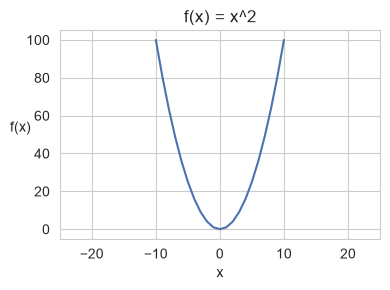

In [5]:
x = np.arange(-10, 11, 1)
y = x**2

plt.figure(figsize=(4, 3))
sns.lineplot(x=x, y=y)
plt.title("f(x) = x^2")
plt.xlabel("x")
plt.ylabel("f(x)", rotation=0)
plt.xlim(-25, 25)
plt.tight_layout()

# plt.savefig("images/function_continuous_example1.png", bbox_inches="tight")
plt.show()

https://www.desmos.com/calculator/i7u4gbnih4

#### Example #2

$f(x) = \sin x$

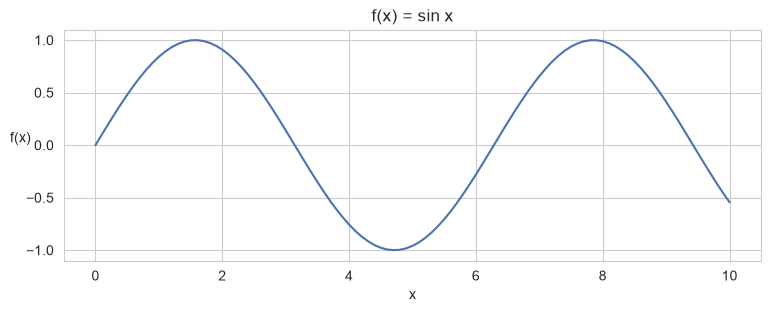

In [6]:
x = np.arange(0, 10.1, 0.1)
y = np.sin(x)

plt.figure(figsize=(9, 3))
sns.lineplot(x=x, y=y)
plt.title("f(x) = sin x")
plt.xlabel("x")
plt.ylabel("f(x)", rotation=0)

plt.show()

https://www.desmos.com/calculator/grjaggafnk

#### Example #3

$f(x) = \vert{x}\vert$

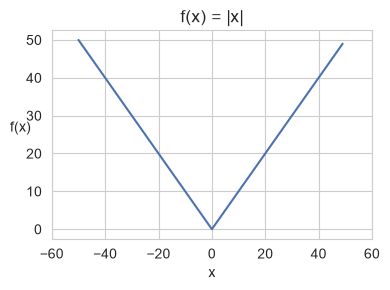

In [7]:
x = np.arange(-50, 50, 1)
y = np.abs(x)

plt.figure(figsize=(4, 3))
sns.lineplot(x=x, y=y)
plt.title("f(x) = |x|")
plt.xlabel("x")
plt.ylabel("f(x)", rotation=0)
plt.xlim(-60, 60)
plt.tight_layout()

# plt.savefig("images/function_continuous_example2.png", bbox_inches="tight")
plt.show()

> **Note**:  
> Even though $f(x) = \vert{x}\vert$ is continuous function, it is **not differentiable at** $x = 0$

#### Example #4

$\displaystyle f(x) = \frac{1}{1 + \mathrm{e}^{-x}}$

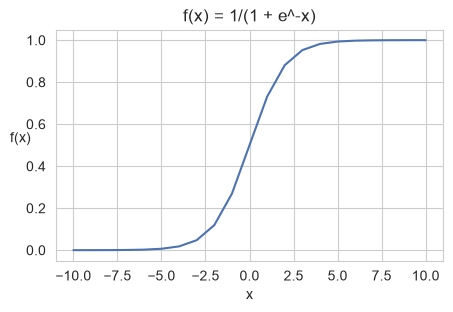

In [8]:
x = np.arange(-10, 11, 1)
y = np.abs(x)

plt.figure(figsize=(5, 3))
sns.lineplot(x=x, y=1 / (1 + np.exp(-x)))
plt.title("f(x) = 1/(1 + e^-x)")
plt.xlabel("x")
plt.ylabel("f(x)", rotation=0)

plt.show()

### 3.6 Discontinuous Function

#### Definition

Criteria for a Discontinuous function:

$$
\large
\lim_{x\;\to\;a^-} f(x) \ne \lim_{x\;\to\;a^+} f(x)
$$

#### Properties

- In layman terms, a function that cannot be drawn **without lifting a pen** is called as Discontinuous Function.
- Mathematically, a function considered as discontinuous function
  - if the **left-hand limit** at $x = a$ **is not equal** to the **right-hand limit** at $x = a$.

$$
\large
\text{Left hand limit} \ne \text{Right hand limit}
$$

### 3.7 Examples Discontinuous Function

#### Example #1

Step Function:

$$
\large
\begin{aligned}
f(x) &= 1  & \text{when}\; x > 0 \\
f(x) &= -1 & \text{when}\; x < 0 \\
f(x) &= 0  & \text{when}\; x = 0
\end{aligned}
$$

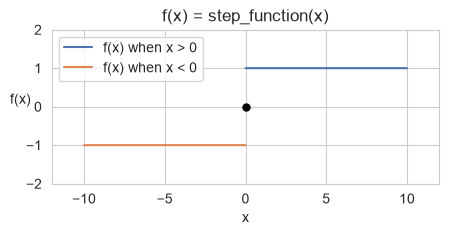

In [9]:
x1 = np.arange(0.001, 10, 0.001)
y1 = np.where(x1 > 0, 1, -1)

x2 = np.arange(-10, -0.001, 0.001)
y2 = np.where(x2 < 0, -1, 1)

plt.figure(figsize=(5, 2))
sns.lineplot(x=x1, y=y1, label="f(x) when x > 0")
sns.lineplot(x=x2, y=y2, label="f(x) when x < 0")
plt.plot(0, 0, marker="o", markersize=5, color="k")
plt.title("f(x) = step_function(x)")
plt.xlabel("x")
plt.ylabel("f(x)", rotation=0)
plt.xlim(-12, 12)
plt.ylim(-2, 2)

plt.show()

#### Example #2

$f(x) = \tan x$

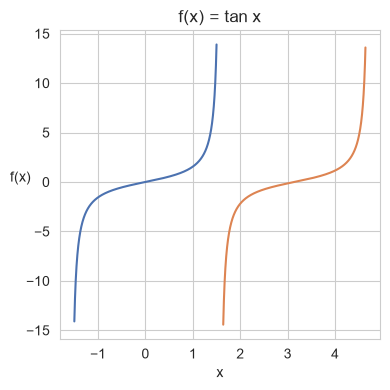

In [10]:
x1 = np.arange(-1.5, 1.5, 0.001)
y1 = np.tan(x1)

x2 = np.arange(1.64, 4.64, 0.001)
y2 = np.tan(x2)

plt.figure(figsize=(4, 4))
sns.lineplot(x=x1, y=y1)
sns.lineplot(x=x2, y=y2)
plt.title("f(x) = tan x")
plt.xlabel("x")
plt.ylabel("f(x)", rotation=0)
plt.tight_layout()

# plt.savefig("images/function_discontinuous_example1.png", bbox_inches="tight")
plt.show()

https://www.desmos.com/calculator/mnik0p4ihv

#### Example #3

$f(x) = \frac{1}{x}$

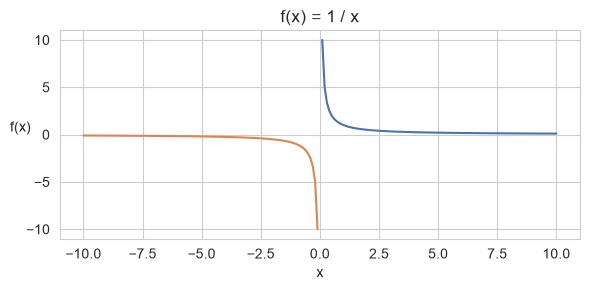

In [11]:
x1 = np.arange(0.1, 10.1, 0.1)
y1 = 1 / x1

x2 = np.arange(-10, -0.01, 0.1)
y2 = 1 / x2

plt.figure(figsize=(6, 3))
sns.lineplot(x=x1, y=y1)
sns.lineplot(x=x2, y=y2)
plt.title("f(x) = 1 / x")
plt.xlabel("x")
plt.ylabel("f(x)", rotation=0)
plt.tight_layout()

# plt.savefig("images/function_discontinuous_example2.png", bbox_inches="tight")
plt.show()

#### Example #4

`ceil()` function in Python.

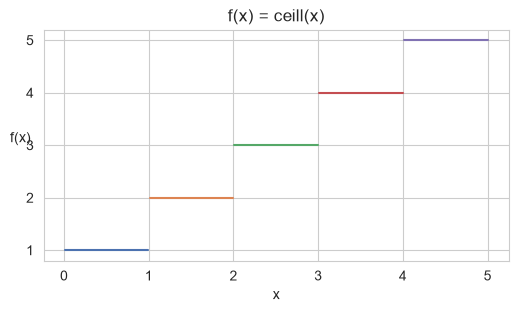

In [12]:
plt.figure(figsize=(6, 3))

for x in range(0, 5):
    x = np.arange(x + 0.01, x + 1, 0.01)
    sns.lineplot(x=x, y=np.ceil(x))

plt.title("f(x) = ceill(x)")
plt.xlabel("x")
plt.ylabel("f(x)", rotation=0)

plt.show()

## 4 Intro to Calculus

### 4.1 Intro to Derivatives

#### Properties

1. Derivatives are calculated using limits.
2. Limits are applied on the continuous functions.
3. Derivatives are the output of Differentiation process applied on continuous function.

#### Derivative of a Function

**Q**: What does the derivative of a function represent?  

**Ans**:

The **slope of the tangent** line to the function's graph at a given point.

#### Slope vs Tangent

**Q**: Why is it useful to find the slope of a tangent?

**Ans**:

1. Slope is zero at minima/maxima point.
2. Slope is calculated using Tangent.

#### Derivatives vs Slope

**Q**: How Derivatives use Slope to calculate minima?

**Ans**:

1. Only continuous functions are differentiable.
2. For a differentiable function, points where slope = 0 are critical points. A minimum occurs only if the second derivative is positive at that point.